# M00-3 | Decomposition: Why PT2E Annotates on the Not-Yet-Decomposed Graph

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m00_export_basics/03_decomposition.ipynb)

An ATen op can be decomposed into lower-level, smaller ops; this is called **decomposition**. The graph that `torch.export` gives by default is not yet decomposed:
`conv2d` is a single `aten.conv2d.default`, and `batch_norm` is a single `aten.batch_norm.default`.
After calling `ep.run_decompositions(table)`, big ops are broken up according to the decomposition table passed in. How deep it goes depends on the table:

| Call | With conv + bn as the example |
|---|---|
| `ep.run_decompositions({})` (empty table; this notebook uses it) | `batch_norm` → `_native_batch_norm_legit_no_training` + `getitem`; `conv2d` unchanged |
| `ep.run_decompositions()` (default table, Core ATen) | `conv2d` also becomes `convolution` |

What this means for quantization: the quantizer looks for "semantic-level" patterns like conv-bn-relu, and once the graph is decomposed they are hard to recognize.
So PT2E annotates **before** decomposing; after convert, when the graph is handed to a backend, the backend decides how deep to decompose.

- **A.** The same ExportedProgram, the graph before and after decomposition.
- **B.** How the ops of the whole graph change, and "how many nodes need to be matched".

In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m00_export_basics")

In [2]:
import torch
from torch.export import export

from common.graph_utils import diff_ops, short
from common.models import example_inputs, get_model
from common.pt2e import quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. The Stem Before and After Decomposition

The model is `TinyConvNet` (4 conv-bn-relu groups in total across stem, block, and head_conv); call `.eval()` first.

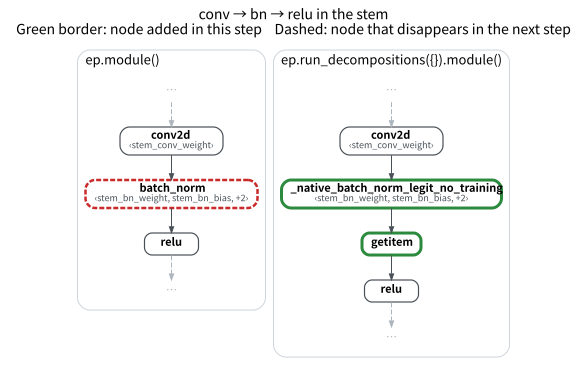

In [3]:
ep = export(get_model("tiny").eval(), example_inputs())
gm_pre = ep.module()                          # PT2E annotates at this level
gm_post = ep.run_decompositions({}).module()  # pass an empty decomposition table
draw_stages([(gm_pre, "ep.module()"), (gm_post, "ep.run_decompositions({}).module()")],
            focus=["conv2d", "batch_norm", "relu"], hops=0, title="conv → bn → relu in the stem")

`batch_norm` (dashed, disappears in the next step) becomes two nodes (green border): `_native_batch_norm_legit_no_training` returns several tensors,
and `getitem` picks out the main output. `conv2d` and `relu` stay as they were.

Note that `run_decompositions` does not modify `ep`; it returns a new ExportedProgram, so `gm_pre` is unaffected.

## B. How the Ops of the Whole Graph Change

In [4]:
print(f"number of nodes (including get_attr, placeholder, output): gm_pre {len(gm_pre.graph.nodes)} → gm_post {len(gm_post.graph.nodes)}")
table(diff_ops(gm_pre, gm_post, "gm_pre", "gm_post", tablefmt="html"))

number of nodes (including get_attr, placeholder, output): gm_pre 47 → gm_post 51


op,gm_pre,gm_post,delta
_native_batch_norm_legit_no_training,0,4,4
batch_norm,4,0,-4
flatten,1,0,-1
getitem,0,4,4
view,0,1,1
adaptive_avg_pool2d,1,1,0
add,1,1,0
conv2d,4,4,0
linear,1,1,0
max_pool2d,2,2,0


In [5]:
def count(gm, op):
    return sum(1 for n in gm.graph.nodes if n.op == "call_function" and short(n.target) == op)


assert count(gm_pre, "batch_norm") == 4 and count(gm_post, "batch_norm") == 0
assert count(gm_post, "_native_batch_norm_legit_no_training") == 4 and count(gm_post, "getitem") == 4
assert count(gm_post, "conv2d") == count(gm_pre, "conv2d")
assert count(gm_pre, "flatten") == 1 and count(gm_post, "view") == 1

- All 4 `batch_norm` become `_native_batch_norm_legit_no_training` + `getitem`.
- The `.flatten(1)` in forward is also replaced by `view`.
- `conv2d`, `relu`, `max_pool2d`, and `linear` stay as they were (the empty table only does the most basic conversions; only the default table breaks conv2d into convolution).

**Question to think about**: to find the conv + bn + relu pattern on `gm_post`, how many nodes need to be matched?

In [6]:
def chain_after(gm, start):
    """Walk down from start along the "only user" and return the op names passed."""
    node, ops = next(n for n in gm.graph.nodes if n.name == start), []
    while node.op == "call_function":
        ops.append(short(node.target))
        if short(node.target) == "relu" or len(node.users) != 1:
            break
        node = next(iter(node.users))
    return ops


pre_chain, post_chain = chain_after(gm_pre, "conv2d"), chain_after(gm_post, "conv2d")
print("gm_pre :", " → ".join(pre_chain))
print("gm_post:", " → ".join(post_chain))
assert len(pre_chain) == 3 and len(post_chain) == 4

gm_pre : conv2d → batch_norm → relu
gm_post: conv2d → _native_batch_norm_legit_no_training → getitem → relu


Before decomposition, 3 nodes are matched; after, it takes 4, with a `getitem` in between that merely "extracts a value".
If a backend uses a deeper decomposition, batch norm is further broken into more arithmetic nodes, and the pattern is even harder to recognize.
So annotation should be done while the semantics of conv + bn + relu are still clear: what the PT2E quantizer receives is the graph at the `ep.module()` level.

## Summary

- `run_decompositions(table)` breaks big ops into small ops, and the table determines how deep; it returns a new ExportedProgram.
- PT2E annotates before decomposition because semantic-level patterns (conv-bn-relu) are easiest to recognize at this level.
- How deep to decompose is the backend's business: for example, the Core ATen set of about 180 ops is for backends that "want to minimize the number of ops they implement".